In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import sklearn
from IPython.display import Image 
%matplotlib inline

In [2]:
URL = "https://github.com/ageron/handson-ml2/blob/master/datasets/housing/housing.csv?raw=true"
df = pd.read_csv(URL)
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
from sklearn.model_selection import train_test_split    
train_set, test_set = train_test_split(df, test_size=0.2, random_state=30)

In [4]:
housing = train_set.drop('median_house_value', axis=1)
housing_labels = train_set['median_house_value'].copy()

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [6]:
# biz buni saqlamadik bu bitta malumotni tozalash ussuli biz hozir buni ishlatmaymiz
housing.dropna(subset=['total_bedrooms'])

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
7186,-118.18,34.03,39.0,609.0,145.0,690.0,134.0,2.9167,<1H OCEAN
7686,-118.10,33.93,35.0,1622.0,302.0,845.0,284.0,4.5769,<1H OCEAN
6332,-117.95,33.99,24.0,1219.0,177.0,610.0,185.0,6.7978,<1H OCEAN
14192,-117.07,32.69,20.0,2192.0,406.0,1766.0,393.0,4.0921,NEAR OCEAN
6611,-118.11,34.18,52.0,3571.0,510.0,1434.0,490.0,5.9009,INLAND
...,...,...,...,...,...,...,...,...,...
500,-122.27,37.85,52.0,1974.0,426.0,875.0,363.0,1.5817,NEAR BAY
12077,-117.64,33.87,2.0,17470.0,2727.0,5964.0,1985.0,6.2308,<1H OCEAN
15277,-117.34,33.06,17.0,2718.0,518.0,815.0,403.0,4.3182,NEAR OCEAN
4517,-118.20,34.04,44.0,1399.0,386.0,1419.0,373.0,1.8224,<1H OCEAN


In [7]:
# 2-chi variant ham bor bizda usha total_bedrooms degan ustunni tasahlab yuborish
housing.drop('total_bedrooms',axis=1)

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,ocean_proximity
7186,-118.18,34.03,39.0,609.0,690.0,134.0,2.9167,<1H OCEAN
7686,-118.10,33.93,35.0,1622.0,845.0,284.0,4.5769,<1H OCEAN
6332,-117.95,33.99,24.0,1219.0,610.0,185.0,6.7978,<1H OCEAN
14192,-117.07,32.69,20.0,2192.0,1766.0,393.0,4.0921,NEAR OCEAN
6611,-118.11,34.18,52.0,3571.0,1434.0,490.0,5.9009,INLAND
...,...,...,...,...,...,...,...,...
500,-122.27,37.85,52.0,1974.0,875.0,363.0,1.5817,NEAR BAY
12077,-117.64,33.87,2.0,17470.0,5964.0,1985.0,6.2308,<1H OCEAN
15277,-117.34,33.06,17.0,2718.0,815.0,403.0,4.3182,NEAR OCEAN
4517,-118.20,34.04,44.0,1399.0,1419.0,373.0,1.8224,<1H OCEAN


In [8]:
# 3-chi variant NaN qiymatlarni boshqa qiymatlar bilan almashtirish
median = housing['total_bedrooms'].median()
housing['total_bedrooms'].fillna(median)

7186      145.0
7686      302.0
6332      177.0
14192     406.0
6611      510.0
          ...  
500       426.0
12077    2727.0
15277     518.0
4517      386.0
5925     1253.0
Name: total_bedrooms, Length: 16512, dtype: float64

# SimpleInputer

## bu bizga har bir ustunga aloxida medium qiymat yoki qanaqadir boshqa uzgaruvchi berib chiqmasdan kutubxona orqali berish yani har biriga aloxida kod yozmasdan kutubxona ishlatish

In [9]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

## bu bizga hamma sonli data uchun median qiymatlarni chiqarali lekin dataga quyib bermaydi

In [10]:
housing_number_data = housing.drop('ocean_proximity', axis=1)# str ustunni uchirish
imputer.fit(housing_number_data)

SimpleImputer(strategy='median')

In [11]:
imputer.statistics_

array([-118.49  ,   34.25  ,   29.    , 2131.    ,  436.    , 1170.    ,
        410.    ,    3.5386])

## dataga bu qiymatlarni quyish uchun transformdan foydalanamiz bu bizga array qaytaradi

In [12]:
X = imputer.transform(housing_number_data)
X

array([[-1.1818e+02,  3.4030e+01,  3.9000e+01, ...,  6.9000e+02,
         1.3400e+02,  2.9167e+00],
       [-1.1810e+02,  3.3930e+01,  3.5000e+01, ...,  8.4500e+02,
         2.8400e+02,  4.5769e+00],
       [-1.1795e+02,  3.3990e+01,  2.4000e+01, ...,  6.1000e+02,
         1.8500e+02,  6.7978e+00],
       ...,
       [-1.1734e+02,  3.3060e+01,  1.7000e+01, ...,  8.1500e+02,
         4.0300e+02,  4.3182e+00],
       [-1.1820e+02,  3.4040e+01,  4.4000e+01, ...,  1.4190e+03,
         3.7300e+02,  1.8224e+00],
       [-1.1780e+02,  3.4150e+01,  1.4000e+01, ...,  3.6990e+03,
         1.1620e+03,  5.5423e+00]])

## biz oldin fitni keyin transformni choqirmasdan ikkalasini birdan chqirsak ham buladi

In [13]:
imputer.fit_transform(housing_number_data)

array([[-1.1818e+02,  3.4030e+01,  3.9000e+01, ...,  6.9000e+02,
         1.3400e+02,  2.9167e+00],
       [-1.1810e+02,  3.3930e+01,  3.5000e+01, ...,  8.4500e+02,
         2.8400e+02,  4.5769e+00],
       [-1.1795e+02,  3.3990e+01,  2.4000e+01, ...,  6.1000e+02,
         1.8500e+02,  6.7978e+00],
       ...,
       [-1.1734e+02,  3.3060e+01,  1.7000e+01, ...,  8.1500e+02,
         4.0300e+02,  4.3182e+00],
       [-1.1820e+02,  3.4040e+01,  4.4000e+01, ...,  1.4190e+03,
         3.7300e+02,  1.8224e+00],
       [-1.1780e+02,  3.4150e+01,  1.4000e+01, ...,  3.6990e+03,
         1.1620e+03,  5.5423e+00]])

In [14]:
housing_tr = pd.DataFrame(X, columns=housing_number_data.columns,
                        index=housing_number_data.index)
housing_tr

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
7186,-118.18,34.03,39.0,609.0,145.0,690.0,134.0,2.9167
7686,-118.10,33.93,35.0,1622.0,302.0,845.0,284.0,4.5769
6332,-117.95,33.99,24.0,1219.0,177.0,610.0,185.0,6.7978
14192,-117.07,32.69,20.0,2192.0,406.0,1766.0,393.0,4.0921
6611,-118.11,34.18,52.0,3571.0,510.0,1434.0,490.0,5.9009
...,...,...,...,...,...,...,...,...
500,-122.27,37.85,52.0,1974.0,426.0,875.0,363.0,1.5817
12077,-117.64,33.87,2.0,17470.0,2727.0,5964.0,1985.0,6.2308
15277,-117.34,33.06,17.0,2718.0,518.0,815.0,403.0,4.3182
4517,-118.20,34.04,44.0,1399.0,386.0,1419.0,373.0,1.8224


In [15]:
housing_category = housing[['ocean_proximity']]

In [16]:
housing_category

,ocean_proximity
7186,<1H OCEAN
7686,<1H OCEAN
6332,<1H OCEAN
14192,NEAR OCEAN
6611,INLAND
...,...
500,NEAR BAY
12077,<1H OCEAN
15277,NEAR OCEAN
4517,<1H OCEAN


In [17]:
housing_category.value_counts()

ocean_proximity
<1H OCEAN          7285
INLAND             5249
NEAR OCEAN         2141
NEAR BAY           1832
ISLAND                5
dtype: int64

# bu yerda bizda harfli data bor bunaqa datani suniy intelekt qabul qilmaydi shu uchun bularni songa utqazish kerak

## buni oddiy usuli ularni 1,2,3,4,5 deb sonlarga ugirish

# OrdinalEncoder

In [18]:
from sklearn.preprocessing import OrdinalEncoder 

## mana bu ishni qildik lekin bu bizni dataga unchayam tushmadi

## chunki 0 okeanga yaqin 1 okeandan umuman uzoq 4esa okeanga yaqin

## bu datamizni suniy ong bir biriga yaqin deb uylaydi sonda berganimiz uchun BU XATO

In [19]:
ordinal = OrdinalEncoder()
housing_category_encoded = ordinal.fit_transform(housing_category)
housing_category_encoded[:10]

array([[0.],
       [0.],
       [0.],
       [4.],
       [1.],
       [1.],
       [1.],
       [1.],
       [3.],
       [1.]])

## bu modelni qachon ishlatsak buladi

In [20]:
# "good, medium, bad" = 0, 1, 2 mana bu holatda bu shunga mos bulardi

# OneHotEncoder

## endi bu bizga tepadigan kora yaxshiroq ishlashga yordam beradi chunki bu har bir ustun uchun aloxida joy yaratadi va matrix tahlab beradi 

## bu qanday ishlaydi 1bu demak u moos keldi 0 qiymat qaytarsa usha categoriyaga tushmadi

In [26]:
from sklearn.preprocessing import OneHotEncoder 

onehotencode = OneHotEncoder()
housing_category_1hotencode = onehotencode.fit_transform(housing_category)
housing_category_1hotencode.toarray()

array([[1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.],
       [1., 0., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

## buni kamchiligi categoriya 10ta 20ta busa data uzun bulib ketadi keyin model sekin ishlashiga olib keladi

# one hot encoderni yana bir usuli get_dummies(pandas) buni avzalligi bu dataframe qaytaradi 

In [27]:
housing_onehot = pd.get_dummies(housing_category)
housing_onehot 

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
7186,1,0,0,0,0
7686,1,0,0,0,0
6332,1,0,0,0,0
14192,0,0,0,0,1
6611,0,1,0,0,0
...,...,...,...,...,...
500,0,0,0,1,0
12077,1,0,0,0,0
15277,0,0,0,0,1
4517,1,0,0,0,0


# create TRANSFORM

## baseestimator bizga fitni ishlashiga yordam beradi

In [38]:
from sklearn.base import BaseEstimator, TransformerMixin

rooms_ix, bedrooms_ix, population_ix, households_ix = 3, 4, 5, 6# bu datadan shu indexlardagilarni ajratib olyapmiz

class CombinedAttributesAdder(BaseEstimator, TransformerMixin):
    def __init__(self, add_bedrooms_per_room = True):
        self.add_bedrooms_per_room = add_bedrooms_per_room
    def fit(self,X, y=None):
        return self
    def transform(self, X):
        rooms_per_household = X[:, rooms_ix] / X[:, households_ix]# honalarni oilaga bulyapmiz shunda har bir oilaga nechta honaligi malum buladi
        population_per_household = X[:, population_ix] / X[:, households_ix]
        if self.add_bedrooms_per_room:# add_bedrooms_per_room ustuni ixtiyoriy buladi
            bedrooms_per_room = X[:, bedrooms_ix] / X[:, rooms_ix]
            return np.c_[X, rooms_per_household, population_per_household, bedrooms_per_room]
        else:
            return np.c_[X, rooms_per_household, population_per_household]



In [39]:
attr_adder = CombinedAttributesAdder()
housing_extra = attr_adder.transform(housing.values)

In [40]:
housing.values[0, :]

array([-118.18, 34.03, 39.0, 609.0, 145.0, 690.0, 134.0, 2.9167,
       '<1H OCEAN'], dtype=object)

# ana endi 3ta yana column qushib berdi

In [42]:
housing_extra[0,:]

array([-118.18, 34.03, 39.0, 609.0, 145.0, 690.0, 134.0, 2.9167,
       '<1H OCEAN', 4.544776119402985, 5.149253731343284,
       0.23809523809523808], dtype=object)

# normalizatsiya

In [43]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,16512.000000,16512.000000,16512.000000,16512.000000,16350.000000,16512.000000,16512.000000,16512.000000
mean,-119.561793,35.625026,28.623849,2637.965661,538.368073,1430.236434,500.155342,3.877301
std,2.001340,2.133272,12.637352,2184.716608,420.997904,1118.175063,381.851846,1.916761
min,-124.350000,32.550000,1.000000,6.000000,1.000000,3.000000,1.000000,0.499900
25%,-121.790000,33.930000,18.000000,1452.000000,297.000000,792.000000,280.000000,2.565175
50%,-118.490000,34.250000,29.000000,2131.000000,436.000000,1170.000000,410.000000,3.538600
75%,-118.000000,37.710000,37.000000,3153.000000,647.000000,1734.000000,606.000000,4.744000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,28566.000000,6082.000000,15.000100


## mana korishimiz mumkin uylarni yoshida minimal 1 maxsimal 52 householdsda min 1 max 6082 bu bir xil deopazonga tugri kelmaydi

# biz ularni bir xil oraliqdagi deopazonga tushirishimiz kerak

# minimum maxsimum skeling bu biz bergan qiymatni qandaydir biz bergan sonnni qandaydir 0 va 1 oraliqqa tushurib oladi

# mana formulasi

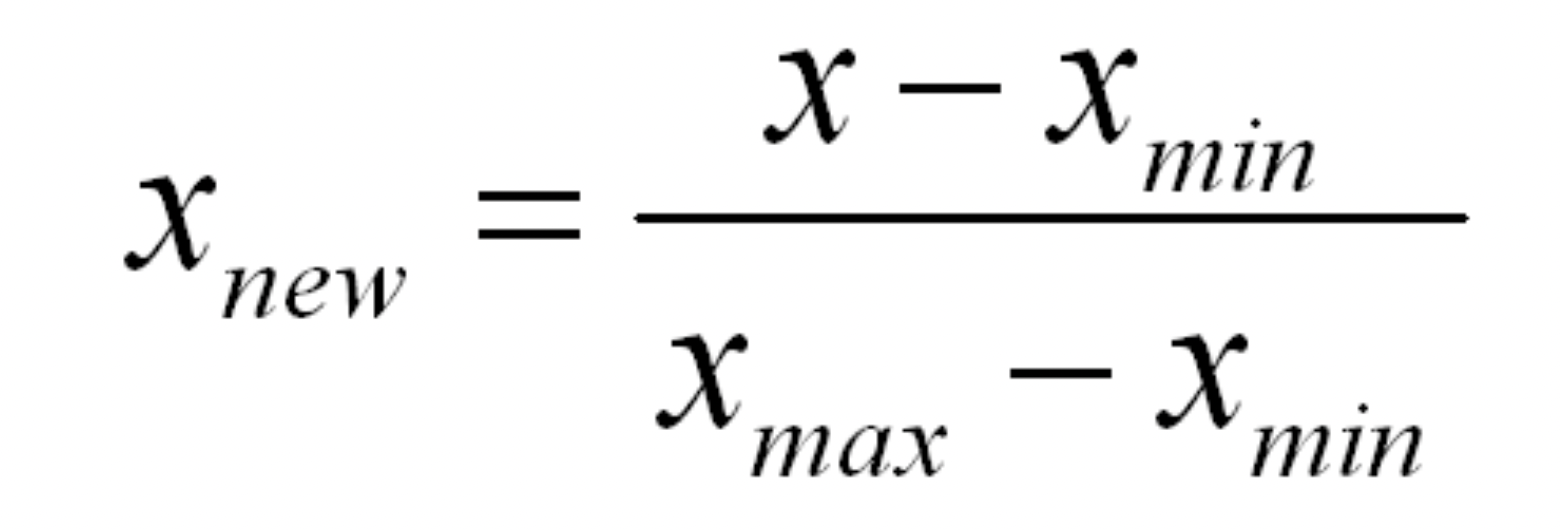

In [44]:
Image('min_max_formula.png')

In [45]:
xmin = housing['median_income'].min()
xmin

0.4999

In [46]:
xmax = housing['median_income'].max()
xmax

15.0001

In [47]:
xnew = (16512.000000-xmin)/(xmax-xmin)
xnew

1138.7084385042965

## bu qulda yozilgan formula buni kutubxonasiyam bor sklearn da

In [48]:
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler()
min_max_scaler.fit_transform(housing_number_data)# faqat sonlar bor datani berdik

array([[0.61454183, 0.15744681, 0.74509804, ..., 0.0240521 , 0.0218714 ,
        0.16667356],
       [0.62250996, 0.14680851, 0.66666667, ..., 0.0294787 , 0.0465384 ,
        0.28116854],
       [0.6374502 , 0.15319149, 0.45098039, ..., 0.02125127, 0.03025818,
        0.43433194],
       ...,
       [0.69820717, 0.05425532, 0.31372549, ..., 0.02842839, 0.06610755,
        0.2633274 ],
       [0.6125498 , 0.15851064, 0.84313725, ..., 0.04957462, 0.06117415,
        0.09120564],
       [0.65239044, 0.17021277, 0.25490196, ..., 0.12939817, 0.19092255,
        0.34774693]])

# endi avvalgi qiymatlar 33,15 va.hk qiymatlar hammasi 0 va 1 oraligida bulib qoldi

# Standartlash

# formulasi = M - orta qiyman sigma - standart ogish

#### 3.4.2 Standard Scaler - standartlash
StandardScaler biroz boshqa usulda ishlaydi. Sonlarni standartlas hcuhn bizga berilgan ustun bo'yicha o'rta qiymat ($\mu$) va standart cheklanish ($\sigma$) talab qilinadi. Har bir qatordag qiymat esa quydagicha hisoblanadi

![](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcQxeMnm1BSa8qyNkCB6wqiYa790XtNxCdM48k_be-9zESUvivv_nuY6SXk8fpJK_psGiA&usqp=CAU)

# bunda qiymatlar 0 va 1 oraligiga tushmaydi lekin qanaydir orta qiymatga keladi

## hammasi bitta deopazonga keladi

In [49]:
from sklearn.preprocessing import StandardScaler

standart_scaler = StandardScaler()
standart_scaler.fit_transform(housing_number_data)

array([[ 0.69045468, -0.74771271,  0.82109487, ..., -0.66202411,
        -0.95892277, -0.50117396],
       [ 0.73042911, -0.79459048,  0.50456328, ..., -0.52340119,
        -0.56608836,  0.36500115],
       [ 0.80538117, -0.76646382, -0.36589859, ..., -0.73357142,
        -0.82535907,  1.52370993],
       ...,
       [ 1.11018621, -1.20242712, -0.91982888, ..., -0.55023143,
        -0.25443974,  0.23002976],
       [ 0.68046107, -0.74302493,  1.21675935, ..., -0.01004921,
        -0.33300662, -1.07210242],
       [ 0.88033323, -0.69145938, -1.15722757, ...,  2.02904925,
         1.73330234,  0.86867869]])

# hozir bu yerda qilgan ishlarimiz malumotlarni tozalash organish juda chalkash buldi lekin buni avtomatlashtirishni yoli bor sklearnda